# Ejemplo conservado de interpretación con LLM

Recuperamos una entrada y una respuesta reales del demo histórico. Se eligió el menor `topic_id` entre las respuestas completadas del caché, sin seleccionar por calidad. **Este ejemplo no pertenece a la comparación integrada de 1.000 reseñas** ni constituye una evaluación de sus 18/28 tópicos.

Se presenta como ilustración del mecanismo: palabras clave y reseñas → descripción y propuesta del modelo. La revisión semántica siguiente es asistida por Codex, no una validación humana. Ejecutar la libreta no envía solicitudes ni consume presupuesto.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/voc").is_dir())
NB_ROOT = REPO / "reports/difusion"
if str(NB_ROOT) not in sys.path: sys.path.insert(0, str(NB_ROOT))
from apoyo_validacion import digest, export_bundle, show_texts
from apoyo_revision import verified_bundle
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})

In [2]:
source_path = NB_ROOT / 'sources/interpretacion-demo-topic0.json'
assert digest(source_path) == '10ec9bd44bf1449dcbe7e9055612ae7062fb17cb54a3863b61306726d60232f1'
snapshot=json.loads(source_path.read_text())
attempt=snapshot['attempt']
request=attempt['request']; response=attempt['response']
original=REPO/snapshot['source']['path']
if original.exists(): assert digest(original)==snapshot['source']['sha256']
print('Caché de origen:',snapshot['cache_counts'], '(conteos de archivo; no tasa de éxito de un estudio)')
display(pd.DataFrame([{'fecha':attempt['created_at'],'modelo':attempt['requested_model'],
 'prompt':attempt['prompt_version'],'temperatura':attempt['generation_parameters']['temperature'],
 'max_tokens':attempt['generation_parameters']['max_tokens'],'estado':attempt['status']}]))

Caché de origen: {'attempts': 37, 'failures': 0} (conteos de archivo; no tasa de éxito de un estudio)


,fecha,modelo,prompt,temperatura,max_tokens,estado
0,2026-10-02T20:50:03+00:00,google/gemini-2.5-flash,app-feature-v1,0,800,completed


## Entrada conservada

El prompt registrado es `app-feature-v1`. El archivo conserva la versión y los parámetros, pero esta instantánea no acredita por sí sola el texto exacto del prompt ni toda la petición de transporte. No lo equiparamos al protocolo posterior. Se muestran los textos completos enviados en este caso.

In [3]:
display(Markdown('**Palabras clave:** '+', '.join(request['keywords'])))
show_texts(request['evidence'],text_column='text')

**Palabras clave:** app falla, problemas app, entrar app, app, apps, app no, abrir aplicación, aplicación no, problemas abrir, reiniciar

## Respuesta y comprobación de referencias

`single_feature` es una autoevaluación del modelo. Que una cita exista comprueba su referencia, no que todas las afirmaciones estén respaldadas ni que el tópico tenga una única funcionalidad.

In [4]:
from apoyo_revision import citation_audit
display(Markdown('**Descripción:** '+response['topic_description']))
display(Markdown('**Propuesta:** '+response['proposed_feature']))
print('Autoevaluación del LLM:',response['assessment'])
audit=citation_audit(attempt)
assert audit['references_exist']
display(pd.DataFrame([audit]))

**Descripción:** Los usuarios reportan problemas recurrentes con la aplicación, incluyendo errores de conexión al servidor, fallos al iniciar sesión, lentitud, bloqueos y la imposibilidad de abrir la aplicación, lo que afecta la experiencia general del usuario y el acceso a funcionalidades esenciales.

**Propuesta:** Mejorar la estabilidad y el rendimiento de la aplicación

Autoevaluación del LLM: single_feature


,provided,cited,unknown_citations,references_exist,semantic_validation
0,6,6,[],True,not established by reference existence


## Revisión asistida de las afirmaciones

Autoría: Codex, 2026-11-06. Este cotejo se limita a las seis reseñas visibles. El modelo resume problemas presentes, pero «estabilidad y rendimiento» es una categoría amplia. La tercera reseña también habla de apertura de cuenta, entrega de tarjeta y atención; por ello, `single_feature` no debe presentarse como una funcionalidad validada. La propuesta de mejorar la aplicación no prueba una causa técnica ni una solución efectiva.

In [5]:
claims=pd.DataFrame([
 {'afirmacion':'Errores de conexión al servidor','evidencias':'e1','lectura_asistida':'Menciona pérdida de contacto con el servidor.'},
 {'afirmacion':'Fallos de acceso y apertura','evidencias':'e1, e2, e4, e6','lectura_asistida':'Describe inicio de sesión, pantalla oscura, app que no abre y actualización no disponible.'},
 {'afirmacion':'Lentitud y bloqueos','evidencias':'e1, e3, e4','lectura_asistida':'Menciona lags, trabas y lentitud.'},
 {'afirmacion':'Una única funcionalidad','evidencias':'e1–e6','lectura_asistida':'No establecido: estabilidad es transversal y e3 añade varios asuntos.'}
])
display(claims)
example=pd.DataFrame([{'componente':'Entrada','contenido':', '.join(request['keywords'])},
 {'componente':'Descripción LLM','contenido':response['topic_description']},
 {'componente':'Propuesta LLM','contenido':response['proposed_feature']},
 {'componente':'Alcance','contenido':'Ejemplo histórico ilustrativo; revisión asistida; no evaluación de la muestra integrada.'}])
display(example)

,afirmacion,evidencias,lectura_asistida
0,Errores de conexión al servidor,e1,Menciona pérdida de contacto con el servidor.
1,Fallos de acceso y apertura,"e1, e2, e4, e6","Describe inicio de sesión, pantalla oscura, ap..."
2,Lentitud y bloqueos,"e1, e3, e4","Menciona lags, trabas y lentitud."
3,Una única funcionalidad,e1–e6,No establecido: estabilidad es transversal y e...


,componente,contenido
0,Entrada,"app falla, problemas app, entrar app, app, app..."
1,Descripción LLM,Los usuarios reportan problemas recurrentes co...
2,Propuesta LLM,Mejorar la estabilidad y el rendimiento de la ...
3,Alcance,Ejemplo histórico ilustrativo; revisión asisti...


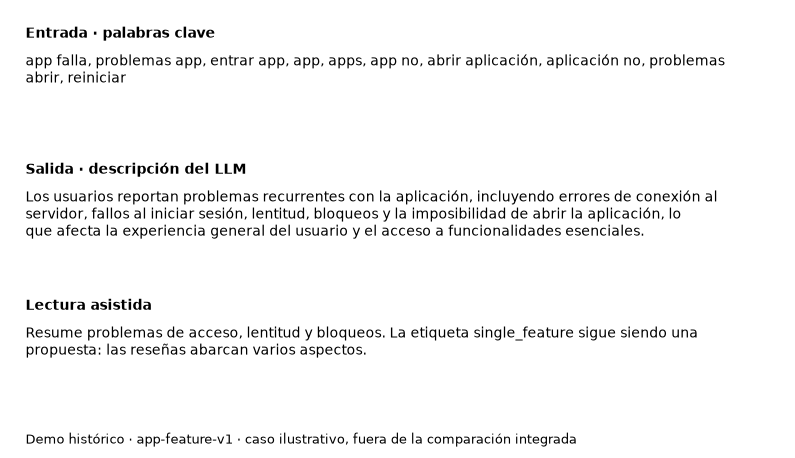

In [6]:
# Figura sencilla y exportable; el expediente JSON conserva todos los textos.
import textwrap
fig, ax=plt.subplots(figsize=(10,5.7));ax.axis('off')
blocks=[('Entrada · palabras clave',', '.join(request['keywords'])),
        ('Salida · descripción del LLM',response['topic_description']),
        ('Lectura asistida','Resume problemas de acceso, lentitud y bloqueos. La etiqueta single_feature sigue siendo una propuesta: las reseñas abarcan varios aspectos.')]
y=.96
for title,text in blocks:
    ax.text(.02,y,title,weight='bold',va='top',transform=ax.transAxes)
    ax.text(.02,y-.06,textwrap.fill(text,100),va='top',transform=ax.transAxes,fontsize=10)
    y-=.31
ax.text(.02,.01,'Demo histórico · app-feature-v1 · caso ilustrativo, fuera de la comparación integrada',fontsize=9,transform=ax.transAxes)
plt.show()

In [7]:
exported=export_bundle(NB_ROOT/'revision-interpretacion-llm.ipynb',{'ejemplo-interpretacion':fig},
 {'ejemplo-interpretacion':example,'cotejo-asistido':claims},
 {'expediente':snapshot,'verificacion':{**audit,'review_origin':'assistant','reviewer':'Codex','human_validated':False,
  'integrated_sample':False,'scope':'historical illustrative example only'}},
 {'snapshot':{'path':str(source_path.relative_to(REPO)),'sha256':digest(source_path)},
  'review_helper':{'path':'reports/difusion/apoyo_revision.py','sha256':digest(NB_ROOT/'apoyo_revision.py')}},
 'Historical saved LLM input/output; traceable example with assistant review, no new inference')

Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/revision-interpretacion-llm/20261106T231320329481Z
